In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd()
while not (ROOT / "src" / "custseg").exists():   # project root = folder that holds the package
    if ROOT == ROOT.parent:
        raise RuntimeError("run the notebook from inside the project folder")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
from IPython.display import Image, Markdown, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
from custseg import config, db
img = lambda p, w=900: display(Image(filename=str(ROOT / p), width=w))

# 07 · Model Evaluation (stage 1 & 2)

In [2]:
pd.read_csv(ROOT / '07_customer_segmentation/results/stage1_best_k_per_family.csv')[['run_id','silhouette','davies_bouldin','stability_bootstrap_ari','size_entropy','min_cluster_share','interpretability','composite']].round(3)

,run_id,silhouette,davies_bouldin,stability_bootstrap_ari,size_entropy,min_cluster_share,interpretability,composite
0,E3-beh-full-pool-gmm-k8,0.207,1.857,0.924,0.678,0.019,0.688,0.602
1,E3-beh-full-pool-kmeans-k8,0.188,1.438,0.956,0.877,0.023,0.750,0.828
2,E3-beh-full-pool-ward-k3,0.347,1.216,0.984,0.363,0.036,0.667,0.700
3,E3-beh-value-experience-gmm-k6,0.187,1.572,0.970,0.831,0.030,0.833,0.825
4,E3-beh-value-experience-kmeans-k6,0.220,1.275,0.991,0.862,0.030,0.917,0.808
5,E3-beh-value-experience-ward-k8,0.226,1.185,0.557,0.917,0.030,0.938,0.608
6,E3-beh-value-lifecycle-gmm-k6,0.125,1.333,0.892,0.832,0.030,0.833,0.605
7,E3-beh-value-lifecycle-kmeans-k6,0.276,1.024,0.989,0.923,0.030,0.917,0.762
8,E3-beh-value-lifecycle-ward-k5,0.305,0.998,0.751,0.857,0.030,0.900,0.740
9,E2-rfm-log-robust-kmeans-k3,0.377,0.895,0.994,0.947,0.190,0.833,0.716


In [3]:
s2 = pd.read_csv(ROOT / '07_customer_segmentation/results/stage2_model_comparison.csv')
s2[['rank','run_id','k','own_silhouette','silhouette','davies_bouldin','calinski_harabasz','stability_bootstrap_ari','size_entropy','interpretability','composite']].round(3)

,rank,run_id,k,own_silhouette,silhouette,davies_bouldin,calinski_harabasz,stability_bootstrap_ari,size_entropy,interpretability,composite
0,1,E2-rfm-log-standard-kmeans-k4,4,0.393,0.209,1.629,28636.423,0.992,0.824,0.875,0.852
1,2,E3-beh-value-lifecycle-kmeans-k6,6,0.276,0.134,4.065,17530.507,0.989,0.923,0.917,0.837
2,3,E2-rfm-log-robust-kmeans-k3,3,0.377,0.201,1.708,22320.484,0.994,0.947,0.833,0.836
3,4,E2-rfm-original-standard-kmeans-k4,4,0.489,0.244,1.380,27864.021,0.997,0.647,0.875,0.827
4,5,E3-beh-value-experience-kmeans-k6,6,0.220,0.075,6.931,13200.099,0.991,0.862,0.917,0.754
5,6,E3-beh-value-lifecycle-ward-k5,5,0.305,0.151,5.150,18133.954,0.751,0.857,0.900,0.663
6,7,E3-beh-value-experience-gmm-k6,6,0.187,0.041,6.895,9505.389,0.970,0.831,0.833,0.639
7,8,E2-rfm-original-robust-kmeans-k3,3,0.621,0.360,2.069,19109.732,0.995,0.345,0.667,0.587
8,9,E3-beh-full-pool-kmeans-k8,8,0.188,0.048,6.321,9842.672,0.956,0.877,0.750,0.580
9,10,E3-beh-value-lifecycle-gmm-k6,6,0.125,-0.052,7.111,10707.788,0.892,0.832,0.833,0.562


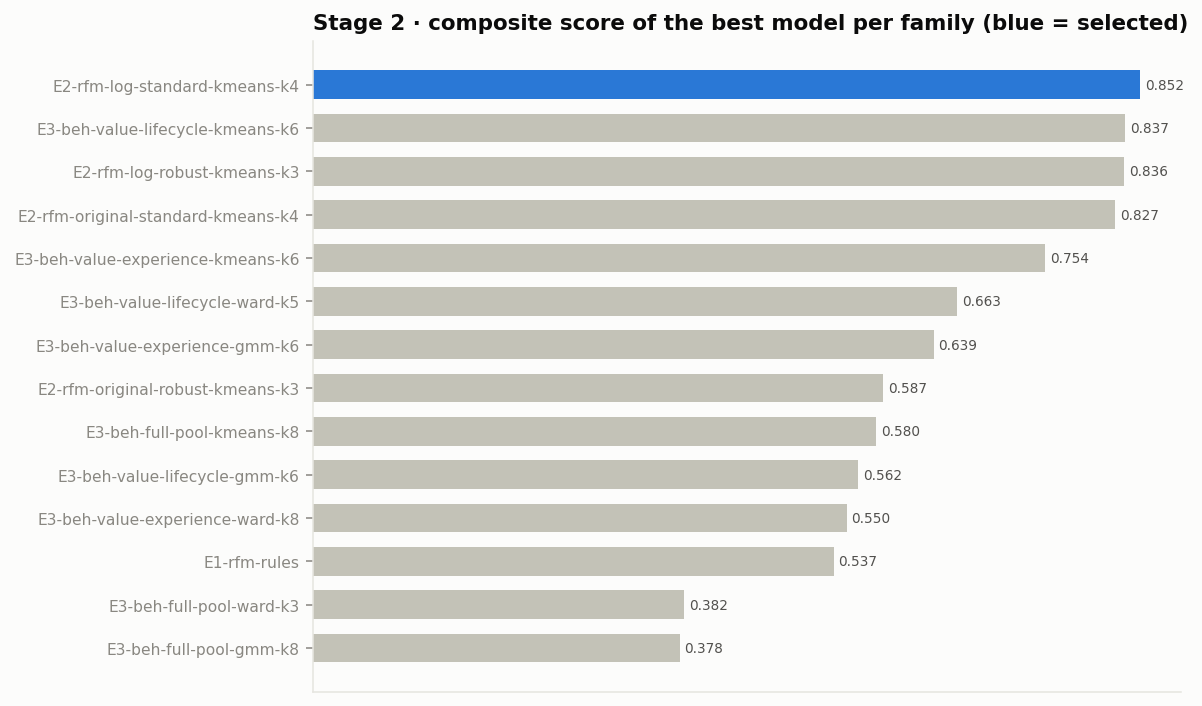

In [4]:
img('07_customer_segmentation/figures/stage2_composite.png', 700)